# Loading WITec project files (`.wip`) with ramantools

This notebook shows how to work directly with a WITec project file, without exporting each map and spectrum as a text table first. The main [ramantools tutorial](ramantools%20tutorial.ipynb) covers everything that happens *after* loading (background subtraction, calibration, normalization, peak fitting); all of it applies unchanged to data loaded from a project file.

Reading `.wip` / `.wid` files uses the [WITecSDK](https://pypi.org/project/WITecSDK/) package, which is an **optional** dependency of ramantools. Install it with either of:

```
pip install ramantools[wip]
pip install WITecSDK
```

# Table of contents
- [Opening a project file](#Opening-a-project-file)
- [What is in the project?](#What-is-in-the-project?)
- [Extracting a map](#Extracting-a-map)
- [Metadata](#Metadata)
- [Running the processing pipeline](#Running-the-processing-pipeline)
- [Extracting single spectra](#Extracting-single-spectra)
- [Masks drawn in Witec Project](#Masks-drawn-in-Witec-Project)
- [Images: fit results and band sums](#Images:-fit-results-and-band-sums)
- [Going beyond the wrapper: the raw SDK object](#Going-beyond-the-wrapper:-the-raw-SDK-object)

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import ramantools as rt
import numpy as np
import pylab as pl

## Opening a project file

The example file is `FLG42_532.wip` in the `test-data` folder (it is large and not part of the git repository, so point `wip_path` at a project file of your own if it is missing).

In [3]:
wip_path = 'test-data/FLG42_532.wip'
wip = rt.wipfile(wip_path)
wip

wipfile('test-data/FLG42_532.wip': 10 maps, 3 spectra, 25 images, 1 masks)

Opening is instant, even for files of several hundred MB: the SDK only reads the directory structure of the file. The actual spectra are decoded when you extract an object.

## What is in the project?

`wip.list()` prints every object in the project, in the order Witec Project shows them. The first column is the object **ID**, which is how you refer to objects from now on. The `kind` column tells you what ramantools can make of the object:

- `map`: a 2D spectral map, extracted with `wip.ramanmap(ID)`
- `spectrum`: a single spectrum, extracted with `wip.singlespec(ID)`
- `mask`: a boolean mask drawn in Witec Project, extracted with `wip.mask(ID)`
- `image`: a numeric image (fit results, band sums, ...), extracted with `wip.image(ID)`
- `text`: the "Information" blocks with the measurement metadata, and user notes
- `bitmap`: video images (not wrapped, see the last section)
- `graph`: other graph types such as line scans or time series (not wrapped)

In [4]:
wip.list()

   ID  kind      shape                caption
   21  bitmap                         Video Image--000
   22  text                           Video Image--000--Information
   28  map       (1600, 120, 50)      Scan Piezo--001--Spec.Data 1
   30  text                           Scan Piezo--001--Information
   33  bitmap                         Video Image--002
   34  text                           Video Image--002--Information
   40  map       (1600, 120, 50)      Scan Piezo--003--Spec.Data 1
   52  spectrum  (1600,)              Scan Piezo--003--Spec.Data 1 (Extracted)
   53  text                           Text
   54  text                           Scan Piezo--003--Information
   58  map       (1600, 120, 50)      Scan Piezo--003--Spec.Data 1 (Sub min)
   87  image     (120, 50)            Scan Piezo--003--Spec.Data 1 (Sub min): 2D-Width-532 (Pos: 2700.0 rel. 1/cm)
   88  image     (120, 50)            Scan Piezo--003--Spec.Data 1 (Sub min): Sum-2690/30-532 (Pos: 2690.0 rel. 1/cm)
   89  i

To show only some kinds, pass them explicitly:

In [5]:
wip.list(kinds = ('map', 'spectrum', 'mask'))

   ID  kind      shape                caption
   28  map       (1600, 120, 50)      Scan Piezo--001--Spec.Data 1
   40  map       (1600, 120, 50)      Scan Piezo--003--Spec.Data 1
   52  spectrum  (1600,)              Scan Piezo--003--Spec.Data 1 (Extracted)
   58  map       (1600, 120, 50)      Scan Piezo--003--Spec.Data 1 (Sub min)
  101  map       (1600, 20, 20)       Scan Piezo--004--Spec.Data 1-anal0
  107  map       (1600, 20, 20)       Scan Piezo--004--Spec.Data 1-anal0 (Sub min)
  121  map       (1600, 20, 20)       Scan Piezo--005--Spec.Data 1-anal0
  142  map       (1600, 20, 20)       Scan Piezo--006--Spec.Data 1
  188  map       (1600, 140, 64)      FLG_42--Scan Piezo--010--Spec.Data 1
  198  spectrum  (1600,)              Scan Piezo--003--Spec.Data 1 (30/32)
  200  spectrum  (1600,)              FLG_42--Scan Piezo--010--Spec.Data 1 (31/33)
  214  map       (1600, 140, 64)      FLG_42--Scan Piezo--010--Spec.Data 1 (Fit Lorentz: Curves)
  241  map       (1600, 140, 64)      

`wip.tree()` shows the same objects as a tree, grouped per scan the way Witec Project displays them. Under each scan comes the raw spectral data, with everything derived from it nested one level deeper: extracted spectra, background-subtracted copies, fit results, band-sum images and masks (user-named masks and images are attached to the scan they were drawn on). Captions are shortened to what they add beyond their parent, and the IDs are the same ones you pass to `wip.ramanmap()`, `wip.singlespec()`, `wip.mask()` and `wip.image()`.

In [6]:
wip.tree()

test-data/FLG42_532.wip  (WITec project v7, 82 objects)
├── Video Image--000
│   ├── [bitmap]     21  Video Image--000
│   └── [text]       22  Information
├── Scan Piezo--001
│   ├── [map]        28  Spec.Data 1  (1600, 120, 50)
│   └── [text]       30  Information
├── Video Image--002
│   ├── [bitmap]     33  Video Image--002
│   └── [text]       34  Information
├── Scan Piezo--003
│   ├── [map]        40  Spec.Data 1  (1600, 120, 50)
│   │   ├── [spectrum]   52  (Extracted)  (1600,)
│   │   ├── [map]        58  (Sub min)  (1600, 120, 50)
│   │   ├── [image]      87  (Sub min): 2D-Width-532 (Pos: 2700.0 rel. 1/cm)  (120, 50)
│   │   ├── [image]      88  (Sub min): Sum-2690/30-532 (Pos: 2690.0 rel. 1/cm)  (120, 50)
│   │   ├── [image]      89  (Sub min): Sum-2720/30-532 (Pos: 2720.0 rel. 1/cm)  (120, 50)
│   │   ├── [image]      90  (Sub min): G-Sum-532 (Pos: 1580.0 rel. 1/cm)  (120, 50)
│   │   ├── [image]      91  (Sub min): 2D-Sum-532 (Pos: 2700.0 rel. 1/cm)  (120, 50)
│   │   ├── 

The SDK-internal objects (coordinate transformations, interpretations, colour profiles) are hidden by default; `wip.tree(show_all = True)` includes them.

The same inventory is available as lists of `(ID, caption)` pairs, which is handy when you want to pick objects in code, e.g. all maps whose caption contains a sample name:

In [7]:
wip.maps

[(28, 'Scan Piezo--001--Spec.Data 1'),
 (40, 'Scan Piezo--003--Spec.Data 1'),
 (58, 'Scan Piezo--003--Spec.Data 1 (Sub min)'),
 (101, 'Scan Piezo--004--Spec.Data 1-anal0'),
 (107, 'Scan Piezo--004--Spec.Data 1-anal0 (Sub min)'),
 (121, 'Scan Piezo--005--Spec.Data 1-anal0'),
 (142, 'Scan Piezo--006--Spec.Data 1'),
 (188, 'FLG_42--Scan Piezo--010--Spec.Data 1'),
 (214, 'FLG_42--Scan Piezo--010--Spec.Data 1 (Fit Lorentz: Curves)'),
 (241, 'FLG_42--Scan Piezo--010--Spec.Data 1 (Fit Lorentz: Curves)')]

In [8]:
[(i, caption) for i, caption in wip.maps if caption.startswith('FLG_42')]

[(188, 'FLG_42--Scan Piezo--010--Spec.Data 1'),
 (214, 'FLG_42--Scan Piezo--010--Spec.Data 1 (Fit Lorentz: Curves)'),
 (241, 'FLG_42--Scan Piezo--010--Spec.Data 1 (Fit Lorentz: Curves)')]

## Extracting a map

`wip.ramanmap(ID)` returns an ordinary `ramanmap` object. You can also pass the exact caption string instead of the ID. Let's take the full-size map of the FLG_42 flake, object 188.

In [9]:
m = wip.ramanmap(188)
m.mapxr

<xarray.DataArray 'Raman intensity' (ramanshift: 1600, height: 140, width: 64)> Size: 115MB
array([[[882., 882., 883., ..., 883., 883., 882.],
        [883., 882., 882., ..., 881., 883., 883.],
        [883., 882., 881., ..., 883., 883., 883.],
        ...,
        [883., 884., 883., ..., 883., 885., 885.],
        [883., 883., 883., ..., 883., 884., 882.],
        [884., 884., 884., ..., 884., 884., 883.]],

       [[883., 882., 882., ..., 880., 883., 882.],
        [882., 882., 882., ..., 881., 881., 881.],
        [882., 882., 883., ..., 883., 882., 882.],
        ...,
        [884., 883., 883., ..., 885., 884., 886.],
        [884., 884., 884., ..., 884., 883., 885.],
        [884., 883., 883., ..., 884., 883., 884.]],

       [[881., 882., 883., ..., 882., 882., 882.],
        [882., 882., 882., ..., 882., 881., 881.],
        [883., 882., 882., ..., 881., 881., 882.],
        ...,
...
        ...,
        [883., 883., 883., ..., 882., 882., 882.],
        [883., 883., 883., ..., 883., 883., 882.],
        [884., 883., 883., ..., 883., 882., 882.]],

       [[879., 878., 879., ..., 878., 878., 878.],
        [879., 878., 879., ..., 879., 878., 879.],
        [878., 879., 880., ..., 878., 879., 879.],
        ...,
        [883., 884., 882., ..., 883., 883., 883.],
        [883., 883., 883., ..., 883., 883., 883.],
        [883., 882., 882., ..., 883., 883., 883.]],

       [[879., 879., 879., ..., 880., 880., 879.],
        [879., 880., 879., ..., 879., 878., 879.],
        [880., 880., 880., ..., 878., 880., 880.],
        ...,
        [882., 882., 882., ..., 883., 883., 883.],
        [884., 882., 881., ..., 883., 884., 883.],
        [882., 883., 883., ..., 882., 884., 883.]]], shape=(1600, 140, 64))
Coordinates:
  * ramanshift  (ramanshift) float64 13kB 1.39e+03 1.392e+03 ... 4.643e+03
  * height      (height) float64 1kB 0.0 0.5036 1.007 1.511 ... 68.99 69.5 70.0
  * width       (width) float64 512B 0.0 0.5079 1.016 1.524 ... 30.98 31.49 32.0
Attributes: (12/16)
    comments:                 raw data loaded \nsource: WITec project object ...
    wipfile name:             test-data/FLG42_532.wip
    units:                    au
    long_name:                Raman intensity
    sample name:              FLG_42
    laser excitation:         532.033 nm
    ...                       ...
    sample positioner Y:      3111.87900018692
    objective name:           Zeiss EC Epiplan-Neofluar Dic 100x / 0.9
    objective magnification:  100.0x
    grating:                  G1: 600 g/mm BLZ=500nm
    map width:                32.0 um
    map height:               70.0 um

This is the same `xarray` container the text-export loader produces: the `ramanshift`, `height` and `width` coordinates are in 1/cm and µm, the metadata is in the attributes, and the data is oriented the way Witec Project displays it.

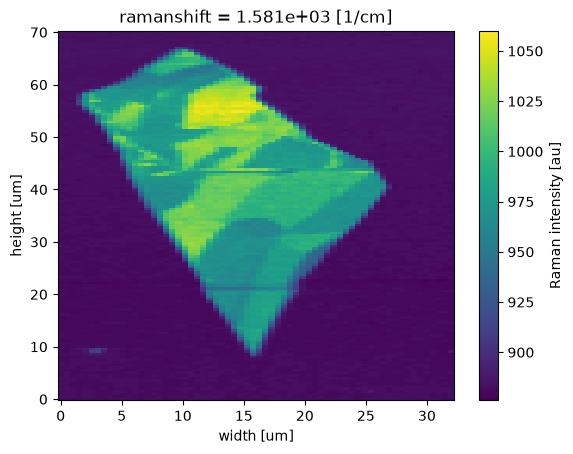

In [10]:
m.mapxr.sel(ramanshift = 1580, method = 'nearest').plot()

Derived maps that you created inside Witec Project (background subtracted copies, "Sub min", fit curves, ...) are extracted the same way. Their caption keeps the suffix, so you can tell them apart from the raw scan:

In [11]:
m_small = wip.ramanmap(107)
m_small.mapname

'Scan Piezo--004--Spec.Data 1-anal0 (Sub min)'

## Metadata

The measurement metadata comes from the "Information" text that Witec stores next to each scan. It is the same text you would export as the info file next to a table export, and it is parsed with the same rules, so the familiar attributes are all there:

In [12]:
m.mapname, m.samplename, m.laser, m.itime, m.grating, m.objname, m.objmagn, m.date, m.time

('FLG_42--Scan Piezo--010',
 'FLG_42',
 532.033,
 5.0,
 'G1: 600 g/mm BLZ=500nm',
 'Zeiss EC Epiplan-Neofluar Dic 100x / 0.9',
 '100.0',
 '2024. február 13., kedd',
 '17:24:28')

In [13]:
m.pixel_x, m.pixel_y, m.size_x, m.size_y

(64, 140, 32.0, 70.0)

The pixel counts and the physical size of the scan are read from the project's coordinate transformation rather than from the text, so they are also correct for cropped or derived maps.

`wip.info(ID)` returns the raw Information text, and `print_metadata()` works as usual:

In [14]:
print(wip.info(188))

FLG_42--Scan Piezo--010

General:
System ID:	100-1100-758
Start Time:	17:24:28
Start Date:	2024. február 13., kedd
Duration:	17h 30m 13s
User Name:	Witec
Sample Name:	FLG_42
Configuration:	Raman CCD1

Image Scan:
Points per Line:	64
Lines per Image:	140
Scan Width [µm]:	32.000
Scan Height [µm]:	70.000
Scan Origin X [µm]:	-0.771
Scan Origin Y [µm]:	-4.121
Scan Origin Z [µm]:	-4.380
Z-Rotation [°]:	-0.200
Scan Speed [s/Line]:	320.000
Retrace Speed [s/Line]:	0.500
Integration Time [s]:	5

UHTS300M:
Excitation Wavelength [nm]:	532.033
Grating:	G1: 600 g/mm BLZ=500nm
Center Wavelength [nm]:	641.197
Spectral Center [rel. 1/cm]:	3200.000

DU970_BV:
Width [Pixels]:	1600
Height [Pixels]:	200
Temperature [°C]:	-59
Cycle Time [s]:	5.00000
Camera Serial Nr.:	13899
AD Converters:	AD1 (16Bit)
Output Amplifier:	EMCCD Gain
Vertical Shift Speed [µs]:	[4.95]
Horizontal Shift Speed [MHz]:	0.05
Preamplifier Gain:	1
EMCCD Gain:	0
ReadMode:	Full Vertical Binning

Signal Stabilization:
Method:	Peak
Actuator 

The processing history records where the data came from:

In [15]:
m.history()

Data modification history:

raw data loaded 
source: WITec project object ID 188: "FLG_42--Scan Piezo--010--Spec.Data 1" 



## Running the processing pipeline

Everything in the main tutorial applies: `remove_bg()`, `calibrate()`, `normalize()`, `crr()` and `rt.peakfit()` all work on the extracted map. Let's run the standard chain on the small background-subtracted map 107.

In [16]:
m_bg, coeff, covar = m_small.remove_bg()
m_norm = m_bg.normalize(1582)
m_crr = m_norm.crr()
m_crr.history()

Data modification history:

raw data loaded 
source: WITec project object ID 107: "Scan Piezo--004--Spec.Data 1-anal0 (Sub min)" 
background subtracted - mode == const, background fit: middle spectrum 
normalized to peak at: 1579.84 in mode == const by a factor of 75.85
replaced cosmic ray values with local mean at 0 coordinates.



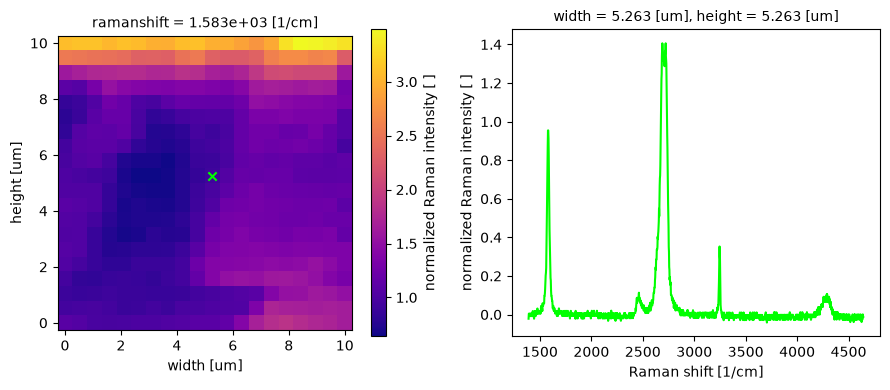

In [17]:
m_crr.plotspec(5, 5, 1582)

## Extracting single spectra

Single spectra, including the ones you extracted from a map inside Witec Project, are returned as `singlespec` objects. Witec names the latter after their pixel coordinates, e.g. `(31/33)` is the spectrum at pixel x = 31, y = 33 of the map.

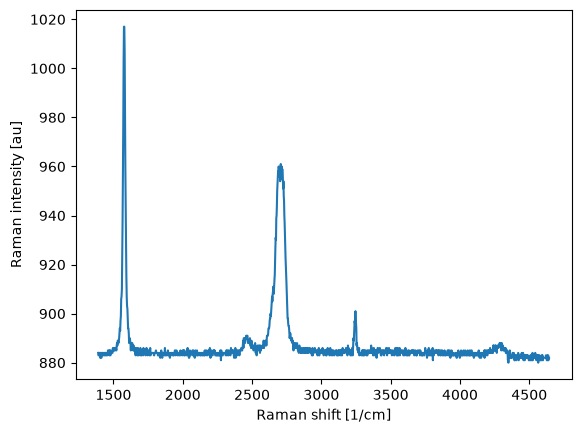

In [18]:
s = wip.singlespec(200)
s.ssxr.plot()

An extracted spectrum has no Information block of its own in the project, so the instrument settings (laser, integration time, grating) are inherited from the parent scan. Its position comes from the spectrum's own coordinates:

In [19]:
s.specname, s.laser, s.itime, s.positioner_x, s.positioner_y, s.positioner_z

('FLG_42--Scan Piezo--010--Spec.Data 1 (31/33)',
 532.033,
 5.0,
 2930.2935800706587,
 3130.3806328043197,
 -4.380000114440918)

We can check that the extracted spectrum really is pixel (31, 33) of the map. Because `mapxr` is flipped along `height` to match the Witec Project orientation, pixel row `y` sits at height index `pixel_y - 1 - y`:

In [20]:
np.allclose(s.counts, m.mapxr.data[:, m.pixel_y - 1 - 33, 31])

True

## Masks drawn in Witec Project

Masks are returned as boolean `xarray` DataArrays on the same `(height, width)` grid as the map they belong to. `True` marks the inside of the mask.

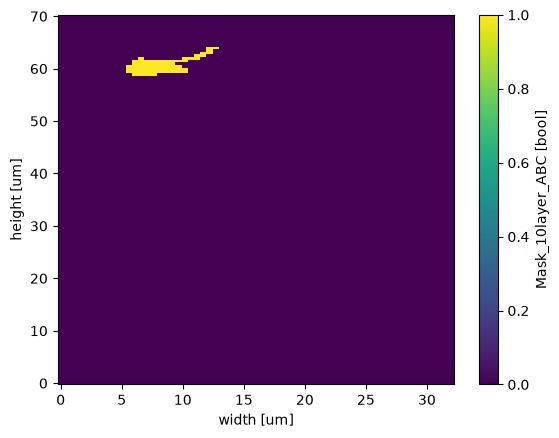

In [21]:
mask = wip.mask(254)
mask.plot()

Because the coordinates match, the mask can be applied to the map directly with `where()`, which replaces everything outside the mask with NaN:

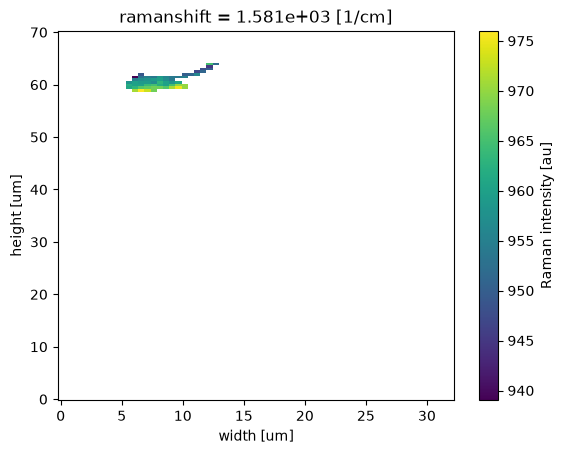

In [22]:
m_masked = m.mapxr.where(mask)
m_masked.sel(ramanshift = 1580, method = 'nearest').plot()

A typical use is averaging all spectra inside the mask:

(1400.0, 3000.0)

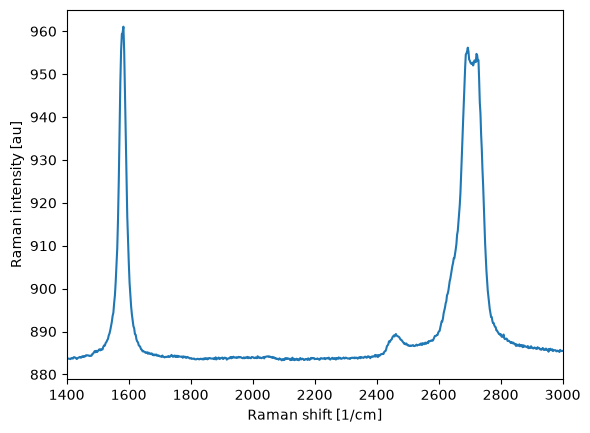

In [23]:
m_masked.mean(dim = ['width', 'height']).plot()
pl.xlim([1400, 3000])

## Images: fit results and band sums

Everything Witec Project computed from a map and stored as an image (peak fits, band sums, peak widths, ...) comes out with `wip.image(ID)` as a 2D DataArray with the Witec unit in `attrs['units']`. Object 208 is the Lorentz peak position of the G peak fitted in Witec Project.

In [24]:
x0 = wip.image(208)
x0.attrs['units']

'rel. 1/cm'

Witec writes a huge sentinel value into pixels where the fit failed, so restrict the range before plotting. Pixels outside the range become NaN and are left blank:

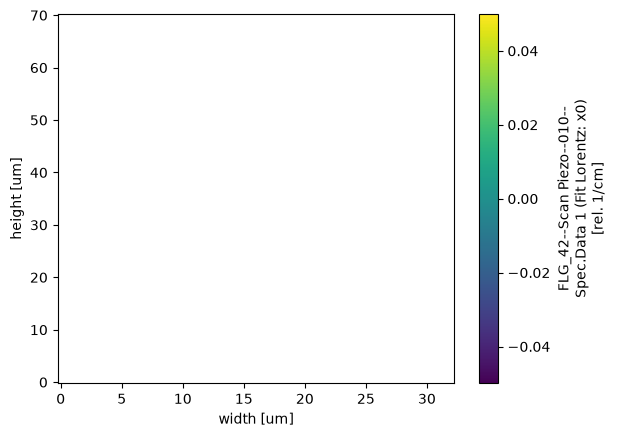

In [25]:
x0.where((x0 > 1560) & (x0 < 1600)).plot(cmap = 'viridis')

The band-sum images Witec computed can be compared to the same quantity calculated from the extracted map, which is also a good check that the map is oriented correctly:

correlation: 0.9973952874872749


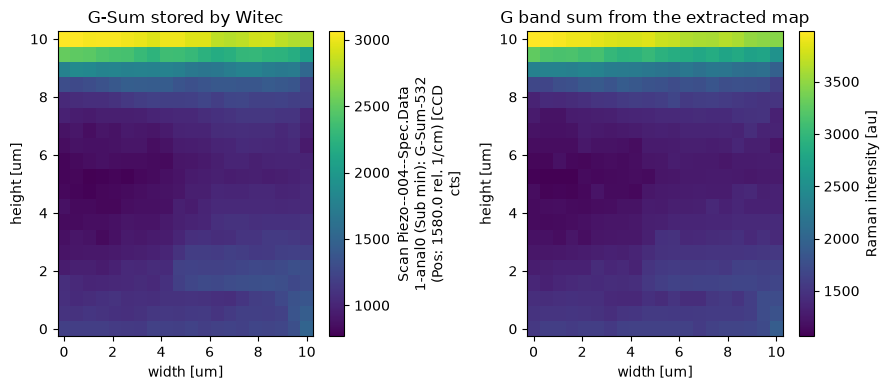

In [26]:
gsum_witec = wip.image(126)
gsum_ours = m_small.mapxr.sel(ramanshift = slice(1500, 1660)).sum('ramanshift')

fig, ax = pl.subplots(1, 2, figsize = (9, 4))
gsum_witec.plot(ax = ax[0]); ax[0].set_title('G-Sum stored by Witec')
gsum_ours.plot(ax = ax[1]); ax[1].set_title('G band sum from the extracted map')
pl.tight_layout()
print('correlation:', np.corrcoef(gsum_witec.data.ravel(), gsum_ours.data.ravel())[0, 1])

`wip.mask()` also accepts a numeric image and thresholds it at `!= 0`, in case you want to turn an image into a mask quickly.

## Going beyond the wrapper: the raw SDK object

Video bitmaps, coordinate transformations, colour profiles and anything else ramantools does not wrap are reachable through the raw WITecSDK `Project` object in `wip.project`. For example, the user notes stored as text objects in this project:

In [27]:
wip.texts

[(22, 'Video Image--000--Information'),
 (30, 'Scan Piezo--001--Information'),
 (34, 'Video Image--002--Information'),
 (53, 'Text'),
 (54, 'Scan Piezo--003--Information'),
 (103, 'Scan Piezo--004--Information'),
 (137, 'Scan Piezo--005--Information'),
 (152, 'Scan Piezo--006--Information'),
 (172, 'ARM_05_newgraphite--Video Stitch--008--Information'),
 (177, 'FLG_42--Video Image--009--Information'),
 (202, 'FLG_42--Scan Piezo--010--Information')]

In [28]:
wip.project.GetDataClassByID(53).PlainText

'Arial CE; 2 mW-tal az 532-es lézer.\nFelveszek egy 90°-os analizátoros map-et.\n\nA 30/32-es pixelben nagyon jól néz ki a 2D csúcs,\n10 réteges, de az ERS csúcs eléggé elkenten csak 3600 körül van.\nEz valamivel a 7réteg fölött van, és sokkkal elkentebb.\n\n22/4 vagy 23/3-> 8 layer körüli stacking fault a 10 rétegben.\n(Ez mondjuk nagyon a minta élén van.\n\n26/93 -> grafén\n\n\n----------\nScan004 -> anal0\nvan benne perfect 7-8 és 10 réteg is.\n\nScan005 -> anal0\nez már a stacking fault lesz.\n\nScan006 -> Felsõ stacking fault anal0\n\n\x00'

See the [WITecSDK documentation](https://pypi.org/project/WITecSDK/) for the full API of the `Project`, `TDGraph`, `TDImage`, `TDBitmap` and `TDText` classes.